# 02. A whole chip: 32 channels from one flux sweep

One VNA sweep of the whole chip at every flux-bias point is enough to characterise every channel of a multiplexer.
This notebook takes such a sweep of the NIST 32-channel chip (26 Sep 2026,
`data/vna/full_comb_flux_sweep_2026-09-26.npz`: $-29$ dBm at the VNA output, 101 flux points over $2\,\Phi_0$,
5.47-5.75 GHz), fits the resonator and the flux response of every channel, and compares the parameter
distributions with those of paper Sec. IV B and Fig. 4, which came from a sweep of the same chip two months earlier.
Channel 1 (resonator 2 of the paper) is checked against the dedicated sweep behind Table I
(`data/vna/res2_flux_power_sweep_2026-09-26.npz`), the usable channels are written into one configuration file,
and six of them are simulated together on one feedline. The notebook runs in about a minute and a half, most of it
in the 32 flux-response fits.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import umux_cmt as uc
from umux_cmt.plotting import *      # use_style, save, SINGLE, DOUBLE, colours, grid
use_style()
DATA, CONFIGS, RESULTS = Path("../data"), Path("../configs"), Path("results")
store = uc.io.ValueStore(RESULTS / "values.json")

import time
import warnings

SWEEP_FILE = DATA / "vna/full_comb_flux_sweep_2026-09-26.npz"
RES2_SWEEP_FILE = DATA / "vna/res2_flux_power_sweep_2026-09-26.npz"
RES2_CONFIG = CONFIGS / "nist_res2_2026-09-26.toml"
CHIP_CONFIG = RESULTS / "configs" / "nist_chip_2026-09-26.toml"

M_NOMINAL = 14.4e-12                     # H, design mutual the flux-bias axis is programmed with
PROMINENCE = 10.0                        # dB, smallest dip depth that counts as a channel
RES2 = 1                                 # survey index of resonator 2, the channel of the paper's Table I
LS = uc.fitting.LS_FIT                   # H, SQUID loop inductance, fixed in the flux-response fits
HALF_WIDTHS = (1.5e6, 1.0e6, 0.75e6)     # Hz, notch-fit window: first try, then the refits
CHI2_MAX = 20                            # reduced chi2 above which a notch fit counts as failed
SEEDS = range(5)                         # seeds of the global flux-response fit
MC_MAX, RMS_MAX = 10e-12, 10e3           # H, Hz: Mc bound of the global fit, largest acceptable rms residual
N_SIM, FLUX_IDX = 6, 0                   # channels and flux point of the multi-channel simulation

atten = store.value("Atten", default=-62.9)      # dB from the VNA output to the chip, fitted in notebook 05
FIG4 = dict(lamb=0.328, Mfr=14.408, Mc=3.686, spacing=6.82, alpha=0.027, P_chip=-89)   # Fig. 4 medians (July; pH, MHz)

## 1. The comb and the cable delay

The file holds $S_{21}$ at one VNA power for 101 flux-bias points $\times$ 10001 frequencies (28 kHz steps). With the
line attenuation $A$ fitted in notebook `05`, $-29$ dBm at the VNA output is
$P_\mathrm{chip} = -29\,\mathrm{dBm} + A \approx -92$ dBm at the chip, 3 dB below the power the paper extracts its
parameters at. The cables add a phase $-2\pi f\tau$ that winds 145 rad over the 280 MHz span, while each resonance
only adds a local wiggle, so a straight line through the unwrapped phase of the zero-flux trace gives the delay $\tau$
of the whole chip (`calculate_tau`). It is the only quantity fitted to the whole trace; everything below is per
channel.

In [2]:
sweep = uc.load_vna_sweep(SWEEP_FILE)
f, s21 = sweep.f, sweep.s21[0]                     # (flux, frequency) at the one power
I_bias = sweep.bias_current(M_NOMINAL)             # coil current of every flux point
P_vna = sweep.powers[0]
P_chip = P_vna + atten

tau = uc.fitting.calculate_tau(f, s21[0])
phase = np.unwrap(np.angle(s21[0])) + 2 * np.pi * f * tau
phase -= np.median(phase)

print(f"{s21.shape[0]} flux points x {s21.shape[1]} frequencies, {f[0] / 1e9:.2f}-{f[-1] / 1e9:.2f} GHz "
      f"in {np.diff(f)[0] / 1e3:.0f} kHz steps")
print(f"flux bias {sweep.flux[0]:.2f}-{sweep.flux[-1]:.2f} nominal Phi0 = {I_bias[0] * 1e3:.2f}-{I_bias[-1] * 1e3:.3f} mA")
print(f"power {P_vna:.0f} dBm at the VNA = {P_chip:.1f} dBm at the chip (A = {atten:.1f} dB)")
print(f"cable delay tau = {tau * 1e9:.2f} ns")

101 flux points x 10001 frequencies, 5.47-5.75 GHz in 28 kHz steps
flux bias 0.00-2.00 nominal Phi0 = 0.00-0.287 mA
power -29 dBm at the VNA = -91.9 dBm at the chip (A = -62.9 dB)
cable delay tau = 82.68 ns


## 2. Finding the channels

`find_resonances` turns the notches into peaks of $-|S_{21}|$ in dB, keeps those deeper than `PROMINENCE` (10 dB),
and of two candidates closer than 1 MHz keeps the deeper one: a channel is 0.5-1.3 MHz wide and its neighbours are
more than 5 MHz away. Below, the zero-flux trace with the detected dips marked, and its phase with the delay removed:
each resonance is a swing of the phase, on top of a slow ripple from standing waves in the cabling.

32 dips between 5507.8 and 5723.8 MHz; spacing 5.60-8.43 MHz
recorded: NChannels 32


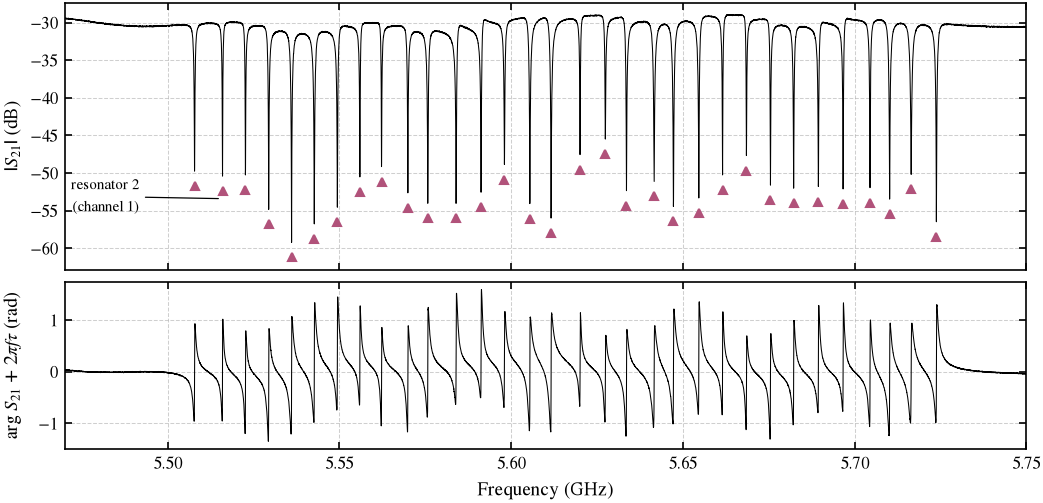

In [3]:
peaks = uc.fitting.find_resonances(f, s21[0], dist=1e6, prominence=PROMINENCE)
f_dip = f[peaks]
n_ch = len(peaks)
print(f"{n_ch} dips between {f_dip[0] / 1e6:.1f} and {f_dip[-1] / 1e6:.1f} MHz; "
      f"spacing {np.diff(f_dip).min() / 1e6:.2f}-{np.diff(f_dip).max() / 1e6:.2f} MHz")
store.record("NChannels", int(n_ch), "{:d}", "channels found in the 09/26 comb sweep (02)")
print(f"recorded: NChannels {store.text('NChannels')}")

db = 20 * np.log10(np.abs(s21[0]))
fig, (ax_db, ax_ph) = plt.subplots(2, 1, figsize=(DOUBLE, 3.4), sharex=True, gridspec_kw={"height_ratios": [1.6, 1]})
ax_db.plot(f / 1e9, db, color=MEASURED, lw=0.5)
ax_db.plot(f_dip / 1e9, db[peaks] - 2, "^", color=ROSE, ms=3.5)
ax_db.annotate(f"resonator 2\n(channel {RES2})", (f_dip[RES2] / 1e9, db[peaks[RES2]] - 3), xytext=(-40, -6),
               textcoords="offset points", ha="right", fontsize=7,
               arrowprops=dict(arrowstyle="-", lw=0.6, shrinkA=1, shrinkB=2))
ax_db.set_ylabel(r"$|S_{21}|$ (dB)")
ax_ph.plot(f / 1e9, phase, color=MEASURED, lw=0.5)
ax_ph.set_ylabel(r"arg $S_{21}$ + $2\pi f\tau$ (rad)")
ax_ph.set_xlabel("Frequency (GHz)")
ax_ph.set_xlim(f[0] / 1e9, f[-1] / 1e9)
for ax in (ax_db, ax_ph):
    grid(ax)
fig.align_ylabels()
save(fig, "02_comb", RESULTS / "figures")
plt.show()

## 3. Resonator parameters of every channel (Fig. 4a, b)

Each notch is fitted on its own in a 3 MHz window centred on its dip, with the delay of Step 1 removed, to
$S_{21} = a e^{i\phi}\left[1 - e^{i\alpha}\,(Q_r/|\hat Q_c|)\,/\,(1 + 2iQ_r(f - f_r)/f_r)\right]$ by the three-stage
circle fit of Probst et al. (`fit_all_resonances`). Fitted per channel: $f_r$, $Q_r$, $|\hat Q_c|$, the asymmetry
angle $\alpha$ and the baseline $a e^{i\phi}$; fixed: $\tau$ and the window. The model uses the diameter-correction
values $Q_c = |\hat Q_c|/\cos\alpha$ and $1/Q_i = 1/Q_r - 1/Q_c$ (Khalil et al.), and a fit counts as implausible
if it failed, if $Q_r$ is outside $500$-$10^5$, if $\alpha$ ran into its $\pm2\pi$ bound or if its reduced $\chi^2$
exceeds 20.

In [4]:
def plausible(Qr, alpha, chi2):
    # False for a failed fit (NaN), Qr outside 500-1e5, alpha on its +-2 pi bound or chi2 above CHI2_MAX
    return (Qr > 500) & (Qr < 1e5) & ~np.isclose(np.abs(alpha), 2 * np.pi) & (chi2 < CHI2_MAX)


comb = uc.fitting.fit_all_resonances(f, s21[0], tau, dist=1e6, width=2 * HALF_WIDTHS[0], prominence=PROMINENCE)
assert np.array_equal(comb.peaks, peaks)
flagged = ~plausible(comb.Qr, comb.alpha, comb.chi2)
print(comb.summary())
print(f"\nimplausible fits: channels {np.flatnonzero(flagged).tolist()}")

  #   fr (MHz)      Qr    |Qc|   alpha  Qc DCM    Qi DCM  BW (kHz)    chi2
  0   5507.818    7321    8191  -0.030    8194     68660       752     0.4
  1   5515.963    9887   10846  -0.095   10896    106753       558     1.9
  2   5522.575    9335   10142   0.168   10288    100848       592     1.7
  3   5529.314    6573    6883   0.197    7019    103429       841     0.9
  4   5536.017    5174    5426   0.058    5436    107332      1070     0.8
  5   5542.723    5028    5255  -0.111    5287    102591      1102     0.9
  6   5549.490    6186    6384  -0.264    6613     95790       897     1.7
  7   5555.995    9220    9979  -0.230   10248     91921       603     1.7
  8   5562.187   10511   11459   0.229   11765     98563       529     1.8
  9   5569.833    7468    7990   0.172    8110     94406       746     1.3
 10   5575.759    5868    6279  -0.114    6320     81951       950     0.7
 11   5584.135    6159    6107  -0.410    6659     82077       907     1.0
 12   5591.406    7107   

Channels 23 and 27 failed. The second stage of the circle fit fits an arctangent to the phase of the circle moved to
the origin, without unwrapping it; for these two the phase crosses $\pm\pi$ about 1.1 MHz from the dip, jumps by
$2\pi$, and the stage returns a $Q_r$ that is far too low, from which the full fit settles in a wrong minimum. A
narrower window keeps the jump outside, so `fit_window` refits a failed window at $\pm1.0$ MHz, then $\pm0.75$ MHz;
Step 4 uses it at every flux point, and the medians below include the two refits.

In [5]:
def fit_window(freq, trace, f_center, tau):
    # notch fit centred on the deepest point within HALF_WIDTHS[0] of f_center, refitted narrower while it fails
    near = np.abs(freq - f_center) <= HALF_WIDTHS[0]
    f_min = freq[near][np.argmin(np.abs(trace[near]))]
    for n_refit, half_width in enumerate(HALF_WIDTHS):
        w = np.abs(freq - f_min) <= half_width
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", RuntimeWarning)     # a failed fit returns NaNs and warns
            fit = uc.fitting.refined_fit(freq[w], trace[w], tau)
        if fit[-1] < CHI2_MAX:
            break
    return fit, n_refit


fr0, Qr0, Qc_abs0, alpha0, chi2_0 = (x.copy() for x in (comb.fr, comb.Qr, comb.Qc_abs, comb.alpha, comb.chi2))
for j in np.flatnonzero(flagged):
    (_, _, fr0[j], Qr0[j], Qc_abs0[j], alpha0[j], chi2_0[j]), n_refit = fit_window(f, s21[0], f_dip[j], tau)
    print(f"channel {j} refitted in +-{HALF_WIDTHS[n_refit] / 1e6:g} MHz: fr {fr0[j] / 1e6:.3f} MHz, Qr {Qr0[j]:.0f}, "
          f"|Qc| {Qc_abs0[j]:.0f}, alpha {alpha0[j]:+.3f}, chi2 {chi2_0[j]:.2f}")
ok = plausible(Qr0, alpha0, chi2_0)
alpha0 = np.angle(np.exp(1j * alpha0))                 # wrapped into (-pi, pi]
Qc0 = Qc_abs0 / np.cos(alpha0)                         # DCM coupling Q
Qi0 = 1 / (1 / Qr0 - 1 / Qc0)

med = {name: np.median(x[ok]) for name, x in (("Qr", Qr0), ("Qc", Qc0), ("Qi", Qi0))}
print(f"\nmedians over the {ok.sum()} plausible fits: Qr {med['Qr']:.0f}, Qc (DCM) {med['Qc']:.0f}, "
      f"Qi (DCM) {med['Qi']:.0f}, alpha {np.median(alpha0[ok]):+.3f} rad, linewidth fr/Qr "
      f"{np.median(fr0[ok] / Qr0[ok]) / 1e3:.0f} kHz")
store.record("QrMedian", med["Qr"], "{:.0f}", "median loaded Q of the chip, 09/26 comb at zero flux (02)")
store.record("QcMedian", med["Qc"], "{:.0f}", "median DCM coupling Q of the chip, 09/26 comb at zero flux (02)")
store.record("QiMedian", med["Qi"], "{:.0f}", "median DCM internal Q of the chip, 09/26 comb at zero flux (02)")
print("recorded: " + ", ".join(f"{k} {store.text(k)}" for k in ("QrMedian", "QcMedian", "QiMedian")))

channel 23 refitted in +-1 MHz: fr 5668.407 MHz, Qr 10026, |Qc| 11082, alpha +0.251, chi2 1.13
channel 27 refitted in +-1 MHz: fr 5696.734 MHz, Qr 7820, |Qc| 8023, alpha -0.342, chi2 0.67

medians over the 32 plausible fits: Qr 6769, Qc (DCM) 7475, Qi (DCM) 90787, alpha -0.038 rad, linewidth fr/Qr 833 kHz
recorded: QrMedian 6769, QcMedian 7475, QiMedian 90787


One fit up close: channel 1 is resonator 2 of the paper. `fit_resonance` returns the same fit as an object that can
draw its model; the data are delay-corrected, so the resonance is a circle in the IQ plane.

fr 5515.9630 MHz, Qr 9887, |Qc| 10846, alpha -0.0951, Qc (DCM) 10896, Qi (DCM) 106753, linewidth 558 kHz


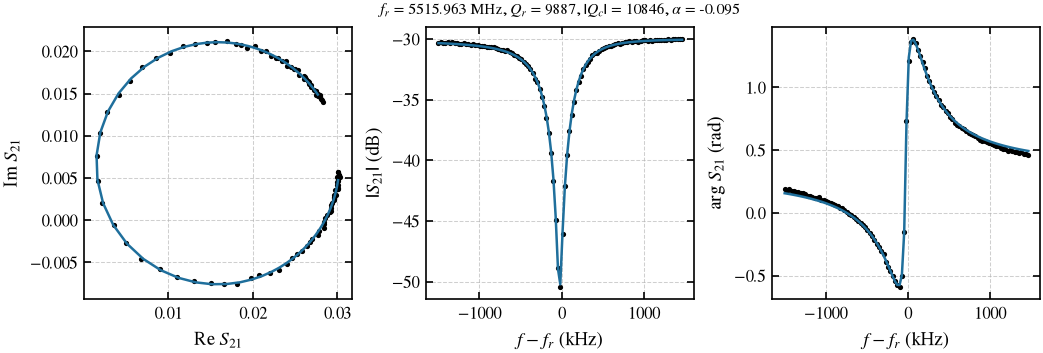

In [6]:
w = np.abs(f - f_dip[RES2]) <= HALF_WIDTHS[0]
s21_w = s21[0, w] * np.exp(2j * np.pi * f[w] * tau)
fit_res2 = uc.fitting.fit_resonance(f[w], s21_w)
print(f"fr {fit_res2.fr / 1e6:.4f} MHz, Qr {fit_res2.Qr:.0f}, |Qc| {fit_res2.Qc_abs:.0f}, alpha {fit_res2.alpha:+.4f}, "
      f"Qc (DCM) {fit_res2.Qc_dcm:.0f}, Qi (DCM) {fit_res2.Qi:.0f}, linewidth {fit_res2.linewidth / 1e3:.0f} kHz")

fig, axes = plt.subplots(1, 3, figsize=(DOUBLE, 2.4))
uc.fitting.plots.notch_panels(f[w], fit_res2, s21=s21_w, axes=axes, fit_kw=dict(color=BLUE))
for ax in axes:
    grid(ax)
save(fig, "02_notch_fit_res2", RESULTS / "figures")
plt.show()

The distributions, as in Fig. 4(a, b): $Q_r$ is set almost entirely by the coupling, $Q_c \approx 5\,000$-$12\,000$,
while $Q_i$ is ten times higher; $\alpha$ scatters around zero by a few tenths of a radian.

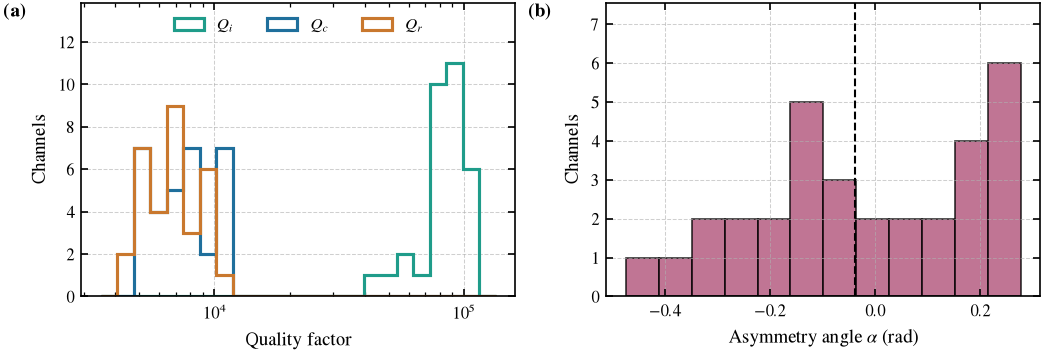

In [7]:
Qs = {"$Q_i$": (Qi0[ok], TEAL), "$Q_c$": (Qc0[ok], BLUE), "$Q_r$": (Qr0[ok], ORANGE)}
all_Q = np.concatenate([q for q, _ in Qs.values()])
bins = np.logspace(np.log10(all_Q.min() * 0.8), np.log10(all_Q.max() * 1.25), 25)

fig, (ax_q, ax_a) = plt.subplots(1, 2, figsize=(DOUBLE, 2.4))
for label, (q, color) in Qs.items():
    ax_q.hist(q, bins=bins, histtype="step", color=color, lw=1.5, label=label)
ax_q.set_xscale("log")
ax_q.set_xlabel("Quality factor")
ax_q.legend(loc="upper center", ncol=3)
ax_a.hist(alpha0[ok], bins=12, color=ROSE, alpha=0.8, edgecolor="black", lw=0.8)
ax_a.axvline(np.median(alpha0[ok]), color="black", ls="--", lw=1)
ax_a.set_xlabel(r"Asymmetry angle $\alpha$ (rad)")
for ax in (ax_q, ax_a):
    ax.set_ylabel("Channels")
    ax.set_ylim(0, ax.get_ylim()[1] * 1.2)
    grid(ax)
panel_labels((ax_q, ax_a))
save(fig, "02_resonator_distributions", RESULTS / "figures")
plt.show()

## 4. The resonance of every channel at every flux

The SQUID moves each resonance periodically in the applied flux, by about 1 MHz peak to peak. Every channel is
fitted at each of the 101 flux points with `fit_window` and the delay of Step 1: the window is centred on the deepest
point within $\pm1.5$ MHz of the channel's zero-flux dip, so it follows the resonance, and narrowed where the fit
fails. The 3232 fits take about 15 s.

In [8]:
t0 = time.perf_counter()
n_flux = len(sweep.flux)
fits = np.empty((n_flux, n_ch, 7))
n_refit = np.zeros((n_flux, n_ch), int)
for j in range(n_ch):
    for k in range(n_flux):
        fits[k, j], n_refit[k, j] = fit_window(f, s21[k], f_dip[j], tau)
_, _, fr, Qr, Qc_abs, alpha, chi2 = np.moveaxis(fits, -1, 0)      # each (flux, channel)
print(f"{n_flux * n_ch} notch fits in {time.perf_counter() - t0:.1f} s")

tracked = np.all(chi2 < CHI2_MAX, axis=0)
refit = n_refit > 0
print(f"refitted in a narrower window: {refit.sum()} windows, in channels "
      + ", ".join(f"{j} ({refit[:, j].sum()})" for j in np.flatnonzero(refit.any(axis=0))))
print(f"reduced chi2 of the accepted fits {chi2[:, tracked].min():.2f}-{chi2[:, tracked].max():.2f}; "
      f"channels with a failed window left: {np.flatnonzero(~tracked).tolist()}")
same = all(np.array_equal(a, b) for a, b in ((fr[0], fr0), (Qr[0], Qr0), (Qc_abs[0], Qc_abs0)))
print(f"zero-flux fits identical to those of Step 3: {same}")
print(f"swing of fr over the flux sweep: {np.ptp(fr, axis=0).min() / 1e3:.0f}-{np.ptp(fr, axis=0).max() / 1e3:.0f} kHz")

3232 notch fits in 13.9 s
refitted in a narrower window: 225 windows, in channels 7 (11), 11 (33), 12 (56), 23 (26), 27 (99)
reduced chi2 of the accepted fits 0.11-7.63; channels with a failed window left: []
zero-flux fits identical to those of Step 3: True
swing of fr over the flux sweep: 975-1126 kHz


Every channel traces the same periodic curve, about 1 MHz peak to peak with a period of one flux quantum, shifted
along the flux axis by the flux its SQUID trapped when it cooled down.

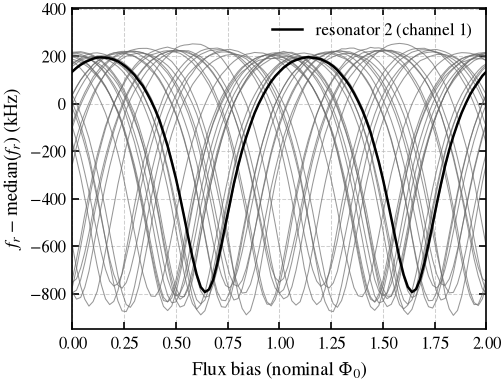

In [9]:
fig, ax = plt.subplots(figsize=(SINGLE, 2.6))
for j in range(n_ch):
    ax.plot(sweep.flux, (fr[:, j] - np.median(fr[:, j])) / 1e3, color=GRAY, lw=0.5, alpha=0.7)
ax.plot(sweep.flux, (fr[:, RES2] - np.median(fr[:, RES2])) / 1e3, color=MEASURED, lw=1.2,
        label=f"resonator 2 (channel {RES2})")
ax.set_xlabel(r"Flux bias (nominal $\Phi_0$)")
ax.set_ylabel(r"$f_r - \mathrm{median}(f_r)$ (kHz)")
ax.set_xlim(sweep.flux[0], sweep.flux[-1])
ax.set_ylim(top=ax.get_ylim()[1] * 1.3)
ax.legend(loc="upper right")
grid(ax)
save(fig, "02_flux_response_all", RESULTS / "figures")
plt.show()

## 5. SQUID parameters of every channel (Fig. 4c-g)

The resonance follows Eq. (2), $f_r(I) = f_0 + (4f_0^2/Z_1)(M_c^2/L_s)\,\lambda\cos\varphi/(1 + \lambda\cos\varphi)$,
with the SQUID phase from Kepler's equation $\varphi + \lambda\sin\varphi = 2\pi(I + I_0)M_\mathrm{fr}/\Phi_0$ and
$I$ the programmed flux times $\Phi_0/14.4$ pH. `fit_flux_response` fits $f_0$, $\lambda$, $M_c$, $M_\mathrm{fr}$
and the offset $I_0$ of each channel (differential evolution from five seeds, polished by least squares) with
$L_s = 24.2$ pH and $Z_1 = 50\,\Omega$ fixed, since $L_s$ enters only as $M_c^2/L_s$; the trapped flux
$\phi_\mathrm{tr} = 2\pi I_\mathrm{tr}M_\mathrm{fr}/\Phi_0$ is the offset measured from the unloaded point
$\varphi = \pi/2$. A fit is unusable if a parameter is not finite, $\lambda$ is outside $(0.1, 0.6)$, $M_c$ sits at
its 10 pH bound or the rms residual exceeds 10 kHz; the 32 fits take about a minute.

In [10]:
t0 = time.perf_counter()
params, rms = np.full((n_ch, 5), np.nan), np.full(n_ch, np.nan)
for j in np.flatnonzero(tracked):
    flux_fit = uc.fitting.fit_flux_response(I_bias, fr[:, j], Ls=LS, seeds=SEEDS, Mc_max=MC_MAX)
    params[j], rms[j] = flux_fit.params, flux_fit.rms
I0, Mfr, Mc, f0, lamb = params.T
phi_tr = uc.fitting.trapped_flux_phase(I0, Mfr, lamb)
print(f"{tracked.sum()} flux-response fits in {time.perf_counter() - t0:.1f} s")

usable = (np.isfinite(params).all(axis=1) & (lamb > 0.1) & (lamb < 0.6) & (Mc > 0) & (Mc < 0.99 * MC_MAX)
          & (rms < RMS_MAX))
good = np.flatnonzero(usable)
spacing = np.diff(np.sort(f0[good]))

print(f"\n{'ch':>3} {'f0 (MHz)':>10} {'lamb':>6} {'Mfr (pH)':>9} {'Mc (pH)':>8} {'phi_tr':>7} {'rms (kHz)':>10}")
for j in range(n_ch):
    print(f"{j:3d} {f0[j] / 1e6:10.3f} {lamb[j]:6.3f} {Mfr[j] * 1e12:9.3f} {Mc[j] * 1e12:8.3f} {phi_tr[j]:7.3f} "
          f"{rms[j] / 1e3:10.2f}" + ("" if usable[j] else "   unusable"))
print(f"\nusable: {len(good)} of {n_ch} channels; median rms residual {np.median(rms[good]) / 1e3:.1f} kHz")

store.record("LambMedian", np.median(lamb[good]), "{:.3f}", "median hysteresis parameter of the chip, 09/26 comb (02)")
store.record("MfrMedian", np.median(Mfr[good]) * 1e12, "{:.2f}", "pH, median flux-ramp mutual of the chip (02)")
store.record("McMedian", np.median(Mc[good]) * 1e12, "{:.2f}", "pH, median SQUID-resonator mutual of the chip (02)")
store.record("SpacingMedian", np.median(spacing) / 1e6, "{:.2f}", "MHz, median spacing of neighbouring f0 (02)")
print("recorded: " + ", ".join(f"{k} {store.text(k)}" for k in ("LambMedian", "MfrMedian", "McMedian", "SpacingMedian")))

this = dict(lamb=np.median(lamb[good]), Mfr=np.median(Mfr[good]) * 1e12, Mc=np.median(Mc[good]) * 1e12,
            spacing=np.median(spacing) / 1e6, alpha=np.median(alpha0[ok]), P_chip=P_chip)
print(f"\n{'medians':<22}{'lamb':>7}{'Mfr (pH)':>10}{'Mc (pH)':>9}{'spacing (MHz)':>15}{'alpha (rad)':>13}"
      f"{'P_chip (dBm)':>14}")
for name, m in (("Fig. 4, July sweep", FIG4), ("this sweep, 26 Sep", this)):
    print(f"{name:<22}{m['lamb']:7.3f}{m['Mfr']:10.3f}{m['Mc']:9.3f}{m['spacing']:15.2f}{m['alpha']:+13.3f}"
          f"{m['P_chip']:14.0f}")

32 flux-response fits in 58.5 s

 ch   f0 (MHz)   lamb  Mfr (pH)  Mc (pH)  phi_tr  rms (kHz)
  0   5508.466  0.328    14.413    3.637   1.236       1.63
  1   5515.690  0.328    14.408    3.657  -2.801       1.33
  2   5522.478  0.330    14.411    3.653  -0.250       1.59
  3   5528.979  0.341    14.407    3.631  -1.668       1.39
  4   5535.682  0.339    14.406    3.629  -2.063       1.84
  5   5542.387  0.342    14.404    3.632  -1.627       2.00
  6   5549.216  0.335    14.410    3.639  -2.826       1.51
  7   5555.881  0.325    14.403    3.667   2.783       1.42
  8   5562.175  0.323    14.403    3.680  -0.027       1.53
  9   5569.526  0.332    14.406    3.690  -2.662       1.39
 10   5576.428  0.336    14.406    3.671   1.074       2.11
 11   5584.091  0.335    14.407    3.672   2.567       1.68
 12   5591.235  0.335    14.407    3.668   2.926       2.10
 13   5597.712  0.334    14.411    3.690  -1.834       2.05
 14   5605.353  0.338    14.411    3.700   0.080       2.09
 15   5

The distributions, as in Fig. 4(c-g), with the rms residual of each fit as a sixth panel: the SQUIDs of one chip are
alike to a few per cent in $\lambda$ and $M_c$ and to 0.1% in $M_\mathrm{fr}$. The medians agree with those of
Fig. 4; $\lambda$ is slightly higher and $M_c$ slightly lower than in July, the direction of the RF dressing at the
3 dB lower power (resonator 2 below), and the median $\alpha$ is small against its scatter in both sweeps (Fig. 4 also
removed the cable phase differently, see `umux_cmt.fitting.comb`). The trapped flux is set by whatever flux each
SQUID caught as it cooled through $T_c$ and is spread over the whole circle, so it has no meaningful median and none
is drawn.

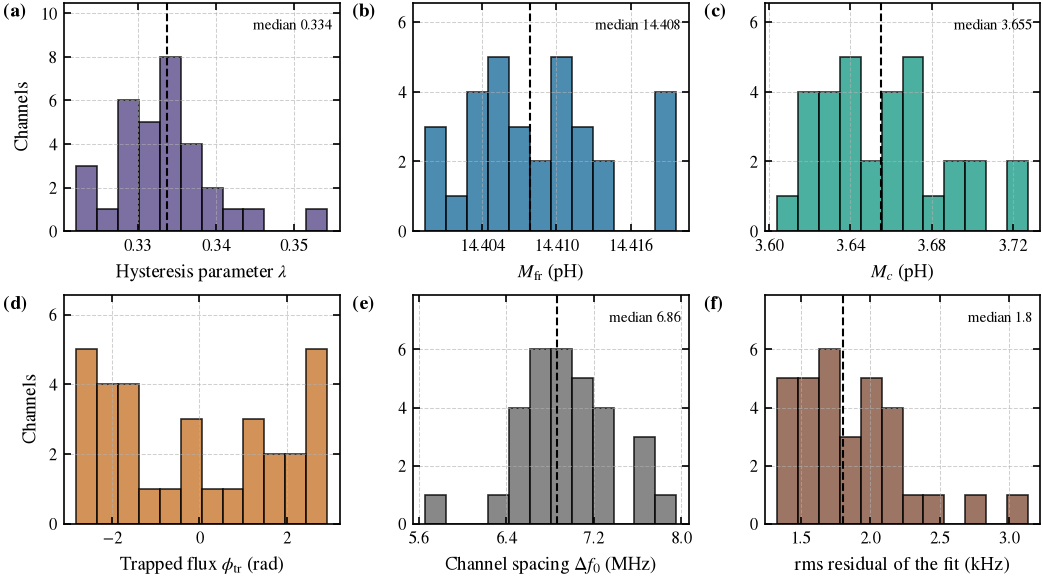

In [11]:
panels = [(lamb[good], r"Hysteresis parameter $\lambda$", VIOLET, "{:.3f}"),
          (Mfr[good] * 1e12, r"$M_\mathrm{fr}$ (pH)", BLUE, "{:.3f}"),
          (Mc[good] * 1e12, r"$M_c$ (pH)", TEAL, "{:.3f}"),
          (phi_tr[good], r"Trapped flux $\phi_\mathrm{tr}$ (rad)", ORANGE, None),
          (spacing / 1e6, r"Channel spacing $\Delta f_0$ (MHz)", GRAY, "{:.2f}"),
          (rms[good] / 1e3, "rms residual of the fit (kHz)", BROWN, "{:.1f}")]

fig, axes = plt.subplots(2, 3, figsize=(DOUBLE, 3.9))
for ax, (x, label, color, fmt) in zip(axes.flat, panels):
    ax.hist(x, bins=12, color=color, alpha=0.8, edgecolor="black", lw=0.8)
    if fmt:
        ax.axvline(np.median(x), color="black", ls="--", lw=1)
        ax.text(0.97, 0.93, "median " + fmt.format(np.median(x)), transform=ax.transAxes, ha="right", va="top",
                fontsize=7)
    ax.set_xlabel(label)
    ax.set_ylim(0, ax.get_ylim()[1] * 1.25)
    ax.xaxis.set_major_locator(plt.MaxNLocator(4))
    grid(ax)
for ax in axes[:, 0]:
    ax.set_ylabel("Channels")
panel_labels(axes.flat, x=-0.22)
save(fig, "02_squid_distributions", RESULTS / "figures")
plt.show()

### Channel 1 against the dedicated sweep of resonator 2

Table I of the paper (`configs/nist_res2_2026-09-26.toml`) comes from a separate sweep of resonator 2 alone, taken
half an hour after the comb with three times finer frequency steps, a delay fitted to that resonance alone and a
parameter extraction at $-26$ dBm. Its $\lambda$ and $M_c$ depend on the probe power, because the probe's RF flux
dresses the SQUID (notebook `05`, Fig. 7), so the dedicated sweep is fitted here at $-30$ and $-28$ dBm, which
bracket the $-29$ dBm of the survey, with `fit_resonance_trace` at every flux point and the same flux-response fit
(about 8 s).

In [12]:
t0 = time.perf_counter()
res2 = uc.load_vna_sweep(RES2_SWEEP_FILE)
rows = [(f"survey, channel {RES2}", P_vna, *params[RES2, [3, 4, 2, 1]], phi_tr[RES2])]
for p in (-30, -28):
    k = res2.power_index(p)
    fr_res2 = np.array([uc.fitting.fit_resonance_trace(res2.f, s).fr for s in res2.s21[k]])
    ff = uc.fitting.fit_flux_response(res2.bias_current(M_NOMINAL), fr_res2, Ls=LS, seeds=SEEDS)
    rows.append(("res2 sweep", res2.powers[k], ff.f0, ff.lamb, ff.Mc, ff.Mfr, ff.phi_tr))
table1 = uc.Config(RES2_CONFIG)
rows.append(("Table I", -26, table1.f0s[0], table1.lambs[0], table1.Mcs[0], table1.Mfrs[0],
             2 * np.pi * table1.Itrs[0] * table1.Mfrs[0] / table1.Phi0))
print(f"dedicated sweep fitted in {time.perf_counter() - t0:.1f} s\n")

print(f"{'':18} {'P_VNA (dBm)':>11} {'f0 (MHz)':>10} {'lamb':>7} {'Mc (pH)':>8} {'Mfr (pH)':>9} {'phi_tr':>7}")
for name, p, f0_, lamb_, Mc_, Mfr_, phi_ in rows:
    print(f"{name:18} {p:11.0f} {f0_ / 1e6:10.4f} {lamb_:7.4f} {Mc_ * 1e12:8.3f} {Mfr_ * 1e12:9.3f} {phi_:7.3f}")

dedicated sweep fitted in 7.0 s

                   P_VNA (dBm)   f0 (MHz)    lamb  Mc (pH)  Mfr (pH)  phi_tr
survey, channel 1          -29  5515.6905  0.3284    3.657    14.408  -2.801
res2 sweep                 -30  5515.6890  0.3308    3.648    14.409  -2.803
res2 sweep                 -28  5515.6889  0.3259    3.666    14.409  -2.798
Table I                    -26  5515.6885  0.3183    3.695    14.409  -2.791


At matched power the survey reproduces the dedicated measurement: $f_0$ to 2 kHz, $M_\mathrm{fr}$ to 0.001 pH,
$\phi_\mathrm{tr}$ to a few mrad, and $\lambda$ and $M_c$ fall between the values at $-30$ and $-28$ dBm. The 3%
lower $\lambda$ and 1% higher $M_c$ of Table I are the RF dressing of its 3 dB higher extraction power, not a
difference between the two sweeps; the chip-wide medians likewise describe the SQUIDs as seen at $-92$ dBm.

## 6. A configuration file for the whole chip

The usable channels go into one configuration file with one entry per channel (format: `configs/README.md`):
$f_0$, $\lambda$, $M_c$ and $M_\mathrm{fr}$ from Step 5; $Q_r$, $|\hat Q_c|$ and $\alpha$ from the zero-flux fits of
Step 3, the fits behind the recorded medians; and the trapped current `relative_I_trapped(I0, Mfr, lamb)`, the
offset from the unloaded point that the loader expects. $L_s = 24.2$ pH is the value the fits assumed (`LS_FIT`;
the FastHenry design value is 22.4 pH), and $L_c = 49.1$ pH, $C_c = 9.4$ fF and $M_\mathrm{in} = 246$ pH are design
values. Loading the file back and asking each channel for its resonance closes the loop with the measured $f_r$ at
zero bias, and with the flux-fit model over the whole sweep.

In [13]:
I_tr = uc.fitting.relative_I_trapped(I0[good], Mfr[good], lamb[good])
CHIP_CONFIG.parent.mkdir(parents=True, exist_ok=True)
uc.write_multichannel_config(CHIP_CONFIG, f0[good], Qr0[good], Qc_abs0[good], alpha0[good], lamb[good], Mc[good],
                             Mfr[good], I_tr, Ls=LS, P_rf_dBm=P_chip)
chip = uc.load_config(CHIP_CONFIG)
print(f"wrote {CHIP_CONFIG}\n")
print(chip.summary())

fr_config = np.array([ch.get_fr() for ch in chip])
fr_fit = np.array([uc.fitting.fr_of_I(0.0, *params[j], Ls=LS) for j in good])
print("\nresonance at zero bias minus the measured fr (kHz):")
for name, model in (("flux-fit model (exact Kepler screening)", fr_fit), ("configuration (series of Eq. 10)", fr_config)):
    d = (model - fr0[good]) / 1e3
    print(f"  {name:<40} median {np.median(d):+5.1f}, range {d.min():+5.1f} to {d.max():+5.1f}")

d_flux = []
for ch, j in zip(chip, good):
    ch.line("FluxRamp").I = I_bias
    d_flux.append(ch.get_fr() - uc.fitting.fr_of_I(I_bias, *params[j], Ls=LS))
    ch.line("FluxRamp").I = 0.0
print(f"configuration minus flux-fit model, every channel and flux point: {np.min(d_flux) / 1e3:+.1f} to "
      f"{np.max(d_flux) / 1e3:+.1f} kHz")

phi_e = np.linspace(-np.pi, np.pi, 721)
series_err = []
for lamb_j in lamb[good]:
    exact = uc.screening_exact(phi_e, 0.0, lamb_j)
    series = uc.screening_factor(phi_e, 0.0, uc.screening_weights(lamb_j))
    series_err.append(np.max(np.abs(series - exact)) / np.ptp(exact))
print(f"screening, series minus exact solution at zero RF power for lamb {lamb[good].min():.3f}-{lamb[good].max():.3f}: "
      f"up to {min(series_err):.2%}-{max(series_err):.2%} of its modulation")

wrote results/configs/nist_chip_2026-09-26.toml

nist_chip_2026-09-26: 32 channel(s), Z0 = 50 Ohm
 ch   f0 (MHz)      Qr      Qc        Qi   alpha   lamb  Mc (pH)  BW (kHz)
  0   5508.466    7321    8194     68660  -0.030  0.328     3.64       752
  1   5515.690    9887   10896    106753  -0.095  0.328     3.66       558
  2   5522.478    9335   10288    100848   0.168  0.330     3.65       592
  3   5528.979    6573    7019    103429   0.197  0.341     3.63       841
  4   5535.682    5174    5436    107332   0.058  0.339     3.63      1070
  5   5542.387    5028    5287    102591  -0.111  0.342     3.63      1102
  6   5549.216    6186    6613     95790  -0.264  0.335     3.64       897
  7   5555.881    9220   10248     91921  -0.230  0.325     3.67       603
  8   5562.175   10511   11765     98563   0.229  0.323     3.68       529
  9   5569.526    7468    8110     94406   0.172  0.332     3.69       746
 10   5576.428    5868    6320     81951  -0.114  0.336     3.67       950
 1

The configuration reproduces the measured resonances to a few kHz, under 1% of a linewidth. The flux-fit model
scatters about the data by its fit residual with no offset; the systematic $-3$ kHz of the configuration comes from
its screening model. The fit solves Kepler's equation exactly, the simulation evaluates the series of Eq. (10) with
the coefficients in `umux_cmt.squid`, and at these $\lambda$ the two differ by up to 0.3-0.4% of the modulation
(last line); with $f_0$ pinned to the unloaded point, that puts the configuration's resonance up to 8 kHz below the
fit's, depending on the flux. The offset is a property of the series as coded, not of the data or the fits, and every
simulation of this configuration carries it (Step 7).

## 7. Six channels on one feedline

The solver integrates all channels of a device at once: each obeys Eq. (23) driven by the incident field
$a_\mathrm{in}$ itself, and the transmitted field is the product of the notches,
$S_{21} = \prod_j\left[1 - (e^{i\alpha_j}/\cos\alpha_j)\sqrt{\kappa_{c,j}/2}\,a_j/a_\mathrm{in}\right]$ (Eq. 24).
This leaves out the interaction through the feedline (the tails of the notches before a channel reduce the field, and
with it the stored energy, that reaches it; reflections between notches are ignored), which is small when the
spacing is many linewidths, here about 7 MHz against 0.6-1.1 MHz. The six lowest channels are swept with the
virtual VNA at the survey's power and bias, and the measured trace is normalised by a cubic in dB fitted to measured
minus simulated $|S_{21}|$ more than 2.5 MHz from every dip, so that the neighbours' tails, which the simulation
contains, stay out of the baseline.

In [14]:
sim_idx = good[:N_SIM]                                      # survey indices of the simulated channels
six = uc.load_config(CHIP_CONFIG, channels=list(range(N_SIM)))
half_spacing = 0.5 * np.median(spacing)
f_sim = np.linspace(fr[FLUX_IDX, sim_idx[0]] - half_spacing, fr[FLUX_IDX, sim_idx[-1]] + half_spacing, 1500)

t0 = time.perf_counter()
s21_vna = uc.steady_state_sweep(six, f_sim, P_chip, flux_ramp_current=I_bias[FLUX_IDX])
print(f"{N_SIM} channels x {len(f_sim)} frequencies, {f_sim[0] / 1e6:.1f}-{f_sim[-1] / 1e6:.1f} MHz at "
      f"{P_chip:.1f} dBm, in {time.perf_counter() - t0:.1f} s")
print(f"spacing / linewidth of the simulated channels: "
      f"{np.diff(fr[FLUX_IDX, sim_idx]).min() / max(ch.linewidth for ch in six):.1f} or more")

band = (f >= f_sim[0]) & (f <= f_sim[-1])
f_meas, db_meas = f[band], 20 * np.log10(np.abs(s21[FLUX_IDX, band]))
db_vna = 20 * np.log10(np.abs(s21_vna))
far = np.min(np.abs(f_meas[:, None] - fr[FLUX_IDX][None, :]), axis=1) > 2.5e6
x = f_meas - f_meas.mean()
mismatch = db_meas - np.interp(f_meas, f_sim, db_vna)
baseline = np.polyval(np.polyfit(x[far], mismatch[far], 3), x)
db_meas -= baseline
print(f"off-resonance level: measured minus CMT at the {far.sum()} far points, {np.std((mismatch - baseline)[far]):.3f} dB "
      f"rms about the cubic")

6 channels x 1500 frequencies, 5504.4-5546.2 MHz at -91.9 dBm, in 2.3 s
spacing / linewidth of the simulated channels: 6.0 or more
off-resonance level: measured minus CMT at the 421 far points, 0.043 dB rms about the cubic


The virtual comb against the measured one: the full band, and each channel up close.

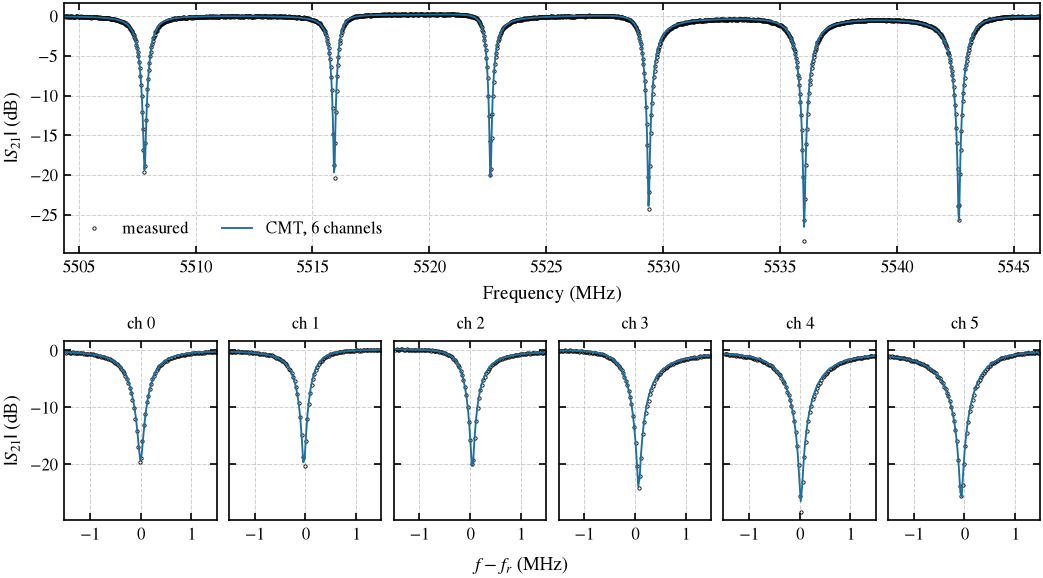

In [15]:
fig = plt.figure(figsize=(DOUBLE, 3.9))
gs = fig.add_gridspec(2, N_SIM, height_ratios=[1.4, 1])
ax_all = fig.add_subplot(gs[0, :])
ax_all.plot(f_meas / 1e6, db_meas, ls="none", marker="o", mfc="none", mew=0.4, ms=1.6, color=MEASURED, label="measured")
ax_all.plot(f_sim / 1e6, db_vna, color=BLUE, lw=0.9, label=f"CMT, {N_SIM} channels")
ax_all.set_xlabel("Frequency (MHz)")
ax_all.set_ylabel(r"$|S_{21}|$ (dB)")
ax_all.set_xlim(f_sim[0] / 1e6, f_sim[-1] / 1e6)
ax_all.legend(loc="lower left", ncol=2)
grid(ax_all)

zoom_axes = []
for i, j in enumerate(sim_idx):
    ax = fig.add_subplot(gs[1, i], sharey=zoom_axes[0] if zoom_axes else None)
    x0 = fr[FLUX_IDX, j]
    m, ms = np.abs(f_meas - x0) < 1.5e6, np.abs(f_sim - x0) < 1.5e6
    ax.plot((f_meas[m] - x0) / 1e6, db_meas[m], ls="none", marker="o", mfc="none", mew=0.4, ms=1.6, color=MEASURED)
    ax.plot((f_sim[ms] - x0) / 1e6, db_vna[ms], color=BLUE, lw=0.9)
    ax.set_title(f"ch {j}", fontsize=8)
    ax.set_xlim(-1.5, 1.5)
    ax.set_xticks([-1, 0, 1])
    if i:
        ax.tick_params(labelleft=False)
    grid(ax)
    zoom_axes.append(ax)
zoom_axes[0].set_ylabel(r"$|S_{21}|$ (dB)")
fig.supxlabel(r"$f - f_r$ (MHz)", fontsize=9)
save(fig, "02_multichannel_s21", RESULTS / "figures")
plt.show()

The virtual VNA uses the solver's default absolute tolerance, $10^{-9}\sqrt{\mathrm J}$, which is above the cavity
field at this power ($|a| \approx 4$-$6\times10^{-10}\sqrt{\mathrm J}$), so its field is only loosely converged. For
numbers we use the settled comb instead: every notch at the fixed point of its equation of motion (`static_response`
at each frequency) multiplied as in Eq. (24), the exact steady state that the time-domain solve reaches only with
tolerances near $10^{-15}\sqrt{\mathrm J}$ and longer settling, minutes for six channels. Both combs are fitted like
the measured one (`fit_all_resonances`, no delay), and every channel is also simulated alone and fitted with
`fit_window`; this takes a few seconds.

In [16]:
def settled_comb(device, f_probe, P, I_fr):
    # Eq. (24) with every notch at the fixed point of its equation of motion
    s = np.ones(len(f_probe), complex)
    for j, ch in enumerate(device):
        phi = I_fr * ch.line("FluxRamp").M / uc.Phi0               # ramp-line flux in Phi0
        s *= [uc.static_response(device, fp, P, phi_grid=[phi], channel=j).s21[0] for fp in f_probe]
    return s


I_now, fr_meas = I_bias[FLUX_IDX], fr[FLUX_IDX, sim_idx]
t0 = time.perf_counter()
s21_set = settled_comb(six, f_sim, P_chip, I_now)
alone = np.array([fit_window(f_sim, settled_comb(uc.load_config(CHIP_CONFIG, channels=[i]), f_sim, P_chip, I_now),
                             fr_meas[i], 0.0)[0] for i in range(N_SIM)])
print(f"settled comb and the six channels alone in {time.perf_counter() - t0:.1f} s")

fit_kw = dict(dist=1e6, width=2 * HALF_WIDTHS[0], prominence=PROMINENCE)
fit_set, fit_vna = (uc.fitting.fit_all_resonances(f_sim, s, 0.0, **fit_kw) for s in (s21_set, s21_vna))
assert len(fit_set) == len(fit_vna) == N_SIM, "one virtual dip per simulated channel"
_, _, fr_alone, Qr_alone, _, _, chi2_alone = alone.T
fr_alone[chi2_alone >= CHI2_MAX] = Qr_alone[chi2_alone >= CHI2_MAX] = np.nan     # a failed fit of a noise-free notch

for ch in six:
    ch.line("FluxRamp").I = I_now
fr_cfg = np.array([ch.get_fr() for ch in six])                   # configuration at zero RF power
for ch in six:
    ch.line("FluxRamp").I = 0.0
Qr_cfg = np.array([ch.Qr for ch in six])

print(f"\n{'':20}{'fr minus measured fr (kHz)':^49}{'Qr fit / config - 1':^20}")
print(f"{'ch':>3}{'above min (kHz)':>17}{'config Er=0':>12}{'alone':>9}{'comb':>9}{'comb, virtual VNA':>19}"
      f"{'alone':>10}{'comb':>10}")
for i, j in enumerate(sim_idx):
    print(f"{j:3d}{(fr_meas[i] - fr[:, j].min()) / 1e3:17.0f}{(fr_cfg[i] - fr_meas[i]) / 1e3:+12.1f}"
          f"{(fr_alone[i] - fr_meas[i]) / 1e3:+9.1f}{(fit_set.fr[i] - fr_meas[i]) / 1e3:+9.1f}"
          f"{(fit_vna.fr[i] - fr_meas[i]) / 1e3:+19.1f}{Qr_alone[i] / Qr_cfg[i] - 1:+10.2%}{fit_set.Qr[i] / Qr_cfg[i] - 1:+10.2%}")
lw = np.array([ch.linewidth for ch in six])
print("\nsettled comb minus measured, in % of each linewidth: "
      + ", ".join(f"{d:+.1f}" for d in 100 * (fit_set.fr - fr_meas) / lw))

settled comb and the six channels alone in 5.1 s

                               fr minus measured fr (kHz)            Qr fit / config - 1 
 ch  above min (kHz) config Er=0    alone     comb  comb, virtual VNA     alone      comb
  0                0        -2.5    +12.4    +12.6              +14.7    +0.02%    +0.89%
  1              929        -4.5     -6.4     -5.6               -1.3    +0.00%    +1.69%
  2              759        +0.4     -3.1     -3.6               +0.3    +0.01%    +2.26%
  3             1024        -3.2     -4.3     -5.0               -3.6    +0.01%    +2.78%
  4             1020        -2.6     -3.5     -3.7               -3.3    +0.01%    +3.14%
  5             1033        -3.7     -4.6     -3.2               -2.9    +0.01%    +2.01%

settled comb minus measured, in % of each linewidth: +1.7, -1.0, -0.6, -0.6, -0.3, -0.3


Settled, five of the six resonances land 3-6 kHz below the measured ones (0.3-1.0% of their linewidths). Read along a
row: the configuration carries the series offset of Step 6 and the flux fit's residual at this bias; the channel alone
adds the second RF dressing ($\lambda$ and $M_c$ were fitted at this power and already contain it, and the simulation
dresses the SQUID once more from the stored energy; notebook `04`); the comb adds the neighbours' tails in the fit
window, within $\pm1.5$ kHz. Channel 0 is 13 kHz high because at zero bias it sits at the sharp bottom of its flux
curve, where averaging the resonance over the RF flux pushes it up by 15 kHz; in the broad upper part of the curve,
where the other five sit, it lowers it by 1-3.5 kHz. The virtual VNA reads 0.3-4.3 kHz above the settled comb, the
error of the solver's default tolerance and settling time, which for channels 1 and 2 happens to cancel the offset.

Alone, every channel returns its configured $Q_r$ to 0.02%; in the comb the fit reads 1-3% high, because a notch with
a flat baseline, fitted in a window that also holds the tails of neighbours 7 MHz away, looks slightly narrower. The
configuration's $Q_r$ come from the same single-notch fits of the measured comb (Step 3), so they probably read 1-3%
high as well, which is small against the spread of Fig. 4(a).

## What to try next

* **Another flux bias.** All 32 SQUIDs share the flux-ramp line, so one current moves every channel. Set
  `FLUX_IDX = 25` (0.5 nominal $\Phi_0$) in the first cell and rerun Step 7: the six channels are simulated at that
  current and compared with the measured trace at that flux, a test of six flux-response fits at once. Channels 3-5
  then sit within 100 kHz of the bottom of their flux curves and come out 4-10 kHz high, as channel 0 does at zero
  bias, while channels 0-2 land 2-7 kHz low.
* **Without the narrower windows.** Set `HALF_WIDTHS = (1.5e6,)` and rerun from Step 3: the failed windows stay
  failed, channels 23 and 27 drop out of the medians, and channels 7, 11, 12, 23 and 27, all with $|\alpha| > 0.2$,
  out of the flux-response fits and the configuration.
* **Your own chip.** Point `SWEEP_FILE` at a VNA flux sweep of your chip (the `.npz` layout is documented in
  `umux_cmt.io`), set `M_NOMINAL` to the design mutual of your flux line, `PROMINENCE` to the depth of your dips and
  `RES2` to a channel you want to look at, and skip the comparison with the dedicated sweep of resonator 2 at the end
  of Step 5. The configuration of Step 6 then works in every simulation of notebook `00`, e.g. with
  `uc.load_config(CHIP_CONFIG, channels=[k])` for one channel.